In [2]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
from parameters import *
from joblib import Parallel, delayed
%matplotlib inline

figures_path = 'figures/'
palette = plt.rcParams['axes.prop_cycle'].by_key()['color']  

In [2]:
def diff_assump(parameters, state_var, dt, elong_fun ):

    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes
    y_free = parameters['Y_max'] - np.sum(y_vec) 

    new_x_vec = x_vec + dt * (-parameters['α']  * r * x_vec  + parameters['β'] * xr_vec* y_free)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec* y_free)
    new_y_vec = y_vec + dt * ( parameters['β'] * xr_vec* y_free - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec


In [3]:
sim_time = 150 
dt = 0.001

In [4]:
sampling = 1000 #resolution of recorded data points to check equilibrium state
results_lp = np.zeros([Rs.shape[0], int(sim_time/dt/sampling),3,N])

 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/l_samples
parameters['γ'] = γ
parameters['l'] = l_samples
parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)
parameters['Y_max'] = N


x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    res = simulation_wrapper(init_state,parameters,diff_assump,R_fernandes, sim_time, dt, [True, sampling]) 
    results_lp[r]= res

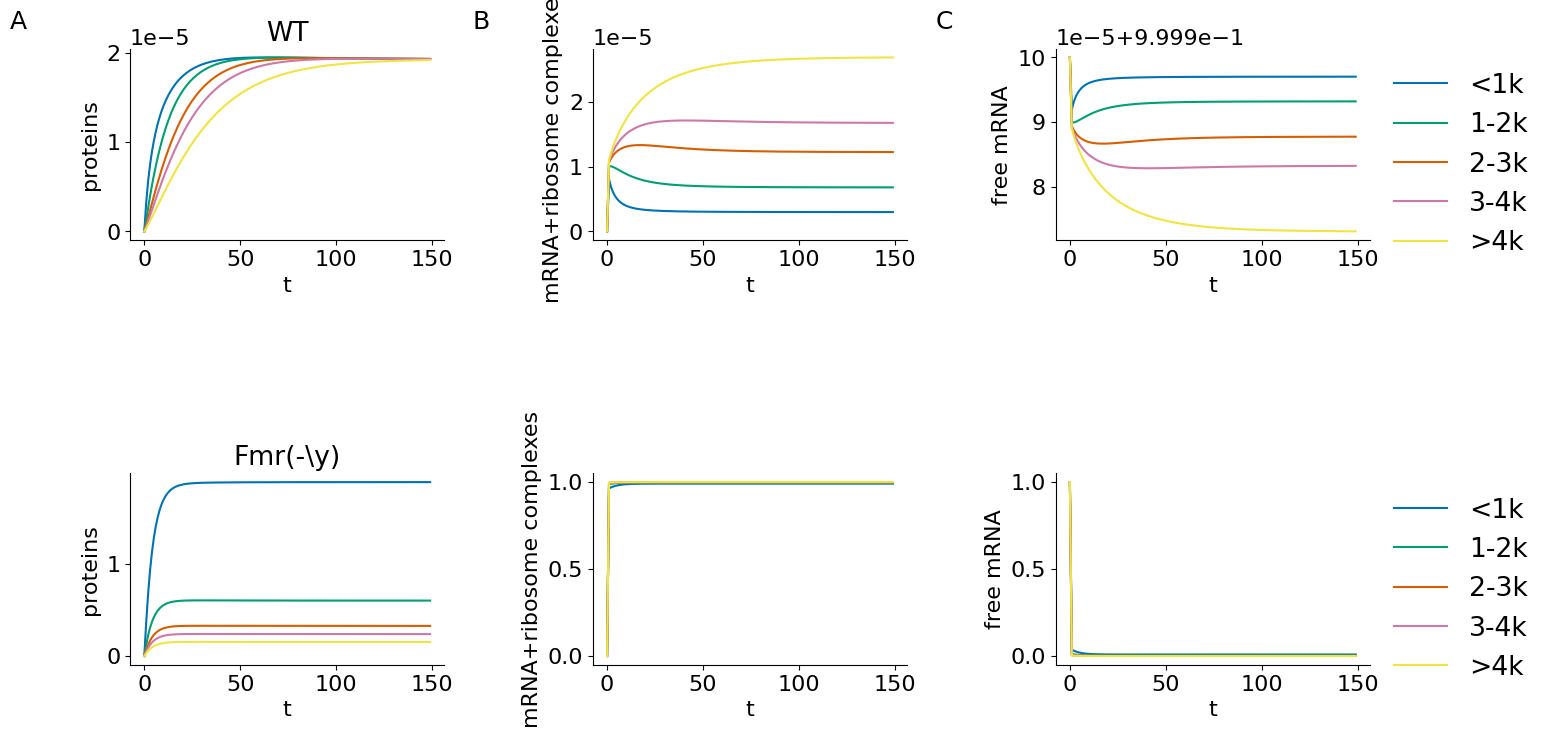

In [5]:
#check that all variables reach their equilibrium state (at minimal and maximal ribosome concetration)

layout = '''
    AABBC
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.2,1,0.2,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
ribo_state= ['WT', 'Fmr(-\y)']
ribo_ind = [0,-1]

for j in range(2): 
    for i in range(3): 
        ax = fig.add_subplot(gs[j*2,i*2])
        if i ==0: 
            ax.set_title(ribo_state[j])
        av1 = np.mean(results_lp[ribo_ind[j],:,2-i,s_1k], axis = 0)
        av2 = np.mean(results_lp[ribo_ind[j],:,2-i,s_2k], axis = 0)
        av3 = np.mean(results_lp[ribo_ind[j],:,2-i,s_3k], axis = 0)
        av4 = np.mean(results_lp[ribo_ind[j],:,2-i,s_4k], axis = 0)
        av5 = np.mean(results_lp[ribo_ind[j],:,2-i,b_4k], axis = 0)

        ax.plot(np.arange(0,sim_time,dt*sampling), av1, label = '<1k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av2, label = '1-2k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av3, label = '2-3k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av4, label = '3-4k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av5, label = '>4k')
        ax.set_xlabel('t')
        ax.set_ylabel(ylabels[i])
        if i == 2: 
            ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
        clear_axes(ax)

plt.show()




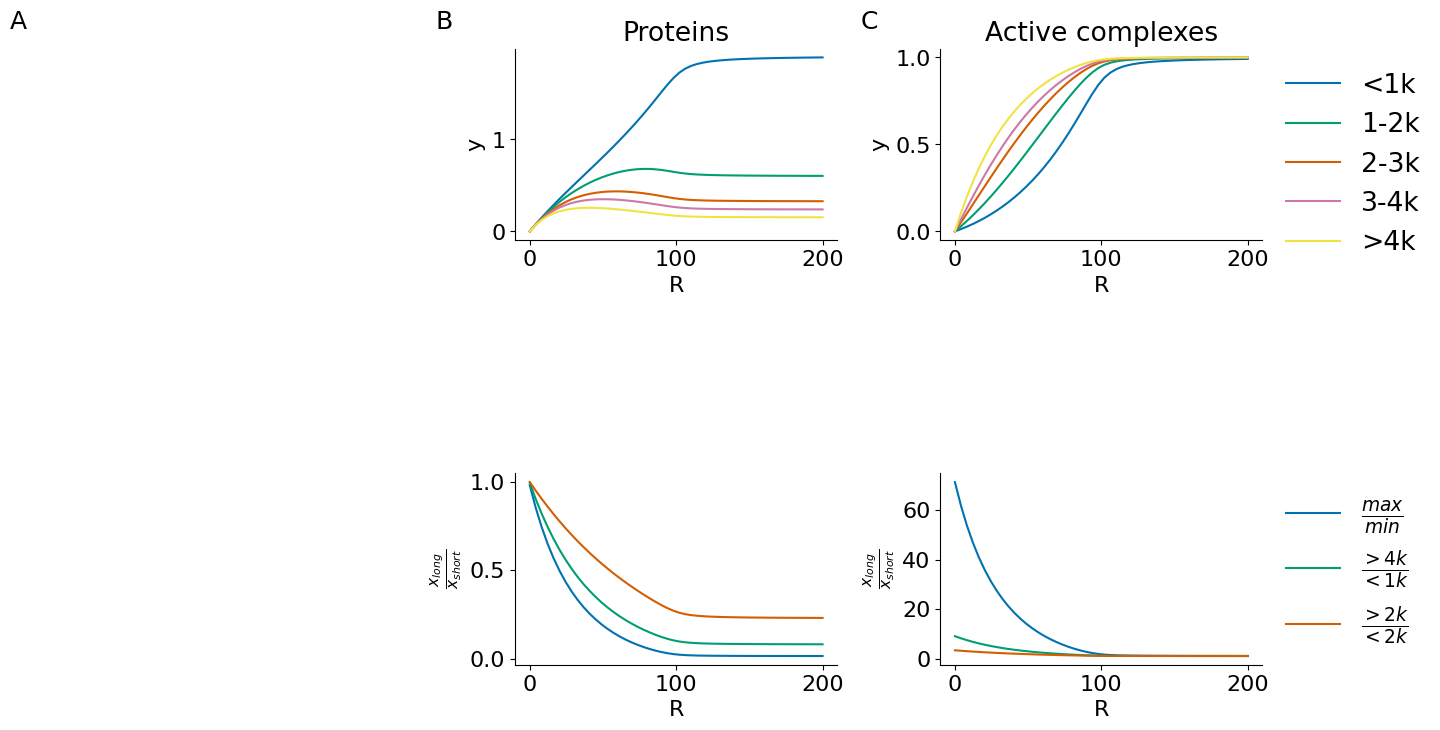

In [6]:
#figure for publication

layout = '''
    AABBCC
    AABBCC
    AABBCC
    '''



fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1, 1]
width_ratios = [1,0.1,1,0.1,1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=.8)
for a in list('ABC'):
    axes[a].set_axis_off()
                 

ax = fig.add_subplot(gs[0,2])
av1 = np.mean(results_lp[:,-1, 2,s_1k], axis = 1)
av2 = np.mean(results_lp[:,-1, 2,s_2k], axis = 1)
av3 = np.mean(results_lp[:,-1, 2,s_3k], axis = 1)
av4 = np.mean(results_lp[:,-1, 2,s_4k], axis = 1)
av5 = np.mean(results_lp[:,-1, 2,b_4k], axis = 1)

ax.plot(Rs, av1, label = '<1k')
ax.plot(Rs, av2, label = '1-2k')
ax.plot(Rs, av3, label = '2-3k')
ax.plot(Rs, av4, label = '3-4k')
ax.plot(Rs, av5, label = '>4k')
ax.set_ylabel('y')
ax.set_xlabel('R')
ax.set_title('Proteins')
clear_axes(ax)

ax = fig.add_subplot(gs[0,4])
av1 = np.mean(results_lp[:,-1, 1,s_1k], axis = 1)
av2 = np.mean(results_lp[:,-1, 1,s_2k], axis = 1)
av3 = np.mean(results_lp[:,-1, 1,s_3k], axis = 1)
av4 = np.mean(results_lp[:,-1, 1,s_4k], axis = 1)
av5 = np.mean(results_lp[:,-1, 1,b_4k], axis = 1)

ax.plot(Rs, av1, label = '<1k')
ax.plot(Rs, av2, label = '1-2k')
ax.plot(Rs, av3, label = '2-3k')
ax.plot(Rs, av4, label = '3-4k')
ax.plot(Rs, av5, label = '>4k')
ax.set_ylabel('y')
ax.set_xlabel('R')
ax.set_title('Active complexes')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)


ax = fig.add_subplot(gs[2,2])
ax.plot(Rs, results_lp[:,-1,2,-1]/results_lp[:,-1,2,0], label = '$\\frac{max}{min}$', color = palette[0])
ax.plot(Rs, np.mean(results_lp[:,-1,2,b_4k], axis = 1)/np.mean(results_lp[:,-1,2,s_1k], axis = 1), label = '$\\frac{>4k}{<1k}$', color = palette[1])
ax.plot(Rs, np.mean(results_lp[:,-1,2,long_ind], axis = 1)/np.mean(results_lp[:,-1,2,short_ind], axis = 1), label = '\\frac{>4k}{<1k}', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)

ax = fig.add_subplot(gs[2,4])
ax.plot(Rs, results_lp[:,-1,1,-1]/results_lp[:,-1,1,0], label = '$\\frac{max}{min}$', color = palette[0])
ax.plot(Rs, np.mean(results_lp[:,-1,1,b_4k], axis = 1)/np.mean(results_lp[:,-1,1,s_1k], axis = 1), label = '$\\frac{>4k}{<1k}$', color = palette[1])
ax.plot(Rs, np.mean(results_lp[:,-1,1,long_ind], axis = 1)/np.mean(results_lp[:,-1,1,short_ind], axis = 1), label = '$\\frac{>2k}{<2k}$', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
#ax.set_ylim(0,1)
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)


#plt.savefig(figures_path+'fig4_diff_ribo_competition_with_amino.pdf')               
plt.show()



**Visualising the effect of different maximal pool size for the amino acid resource**

In [12]:
Ys = np.logspace(1,5, num = 20)#np.arange(int(N/4),int(N*4), int(N/4))
Rs = np.linspace(1,200, num = 20)

x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 

def simulation_wrapper_parallel(params, sim_time, dt): 
    
    parameters = dict()
    parameters['α'] = α
    parameters['β'] = α / l_samples
    parameters['γ'] = γ
    parameters['l'] = l_samples
    parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)
    parameters['Y_max'] =  params[0]
    

    parameters['R'] = params[1]


    x0 = np.ones([N])*x_init
    init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 

    next_t = init_state

    for t in range(int(sim_time/dt)):
        next_t = diff_assump(parameters, next_t, dt, R_fernandes)
    res = next_t

    return res


        
results_ys = Parallel(n_jobs=-1)(delayed(simulation_wrapper_parallel)([y,r], sim_time, dt) for y in Ys for r in Rs)
results_h = np.asarray(results_ys)

results_ys = np.reshape(results_h,(Ys.shape[0], Rs.shape[0],3,N))

np.save('diff_data/ribo_amino_resource_interaction.npy',results_ys)

In [ ]:
#check that all variables reach their equilibrium state (at minimal and maximal ribosome concetration)

layout = '''
    AABBC
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.2,1,0.2,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
ribo_state= ['WT', 'Fmr(-\y)']
ribo_ind = [0,-1]

for j in range(2): 
    for i in range(3): 
        ax = fig.add_subplot(gs[j*2,i*2])
        if i ==0: 
            ax.set_title(ribo_state[j])
        av1 = np.mean(results_ys[0,ribo_ind[j],:,2-i,s_1k], axis = 0)
        av2 = np.mean(results_ys[0,ribo_ind[j],:,2-i,s_2k], axis = 0)
        av3 = np.mean(results_ys[0,ribo_ind[j],:,2-i,s_3k], axis = 0)
        av4 = np.mean(results_ys[0,ribo_ind[j],:,2-i,s_4k], axis = 0)
        av5 = np.mean(results_ys[0,ribo_ind[j],:,2-i,b_4k], axis = 0)

        ax.plot(np.arange(0,sim_time,dt*sampling), av1, label = '<1k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av2, label = '1-2k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av3, label = '2-3k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av4, label = '3-4k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av5, label = '>4k')
        ax.set_xlabel('t')
        ax.set_ylabel(ylabels[i])
        if i == 2: 
            ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
        clear_axes(ax)
        if i == 1: 
            ax.set_title('Low aminoacids')

plt.show()


layout = '''
    AABBC
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.2,1,0.2,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
ribo_state= ['WT', 'Fmr(-\y)']
ribo_ind = [0,-1]

for j in range(2): 
    for i in range(3): 
        ax = fig.add_subplot(gs[j*2,i*2])
        if i ==0: 
            ax.set_title(ribo_state[j])
        av1 = np.mean(results_ys[-1,ribo_ind[j],:,2-i,s_1k], axis = 0)
        av2 = np.mean(results_ys[-1,ribo_ind[j],:,2-i,s_2k], axis = 0)
        av3 = np.mean(results_ys[-1,ribo_ind[j],:,2-i,s_3k], axis = 0)
        av4 = np.mean(results_ys[-1,ribo_ind[j],:,2-i,s_4k], axis = 0)
        av5 = np.mean(results_ys[-1,ribo_ind[j],:,2-i,b_4k], axis = 0)

        ax.plot(np.arange(0,sim_time,dt*sampling), av1, label = '<1k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av2, label = '1-2k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av3, label = '2-3k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av4, label = '3-4k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av5, label = '>4k')
        ax.set_xlabel('t')
        ax.set_ylabel(ylabels[i])
        if i == 2: 
            ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
        clear_axes(ax)
        if i == 1: 
            ax.set_title('Abundant aminoacids')

plt.show()




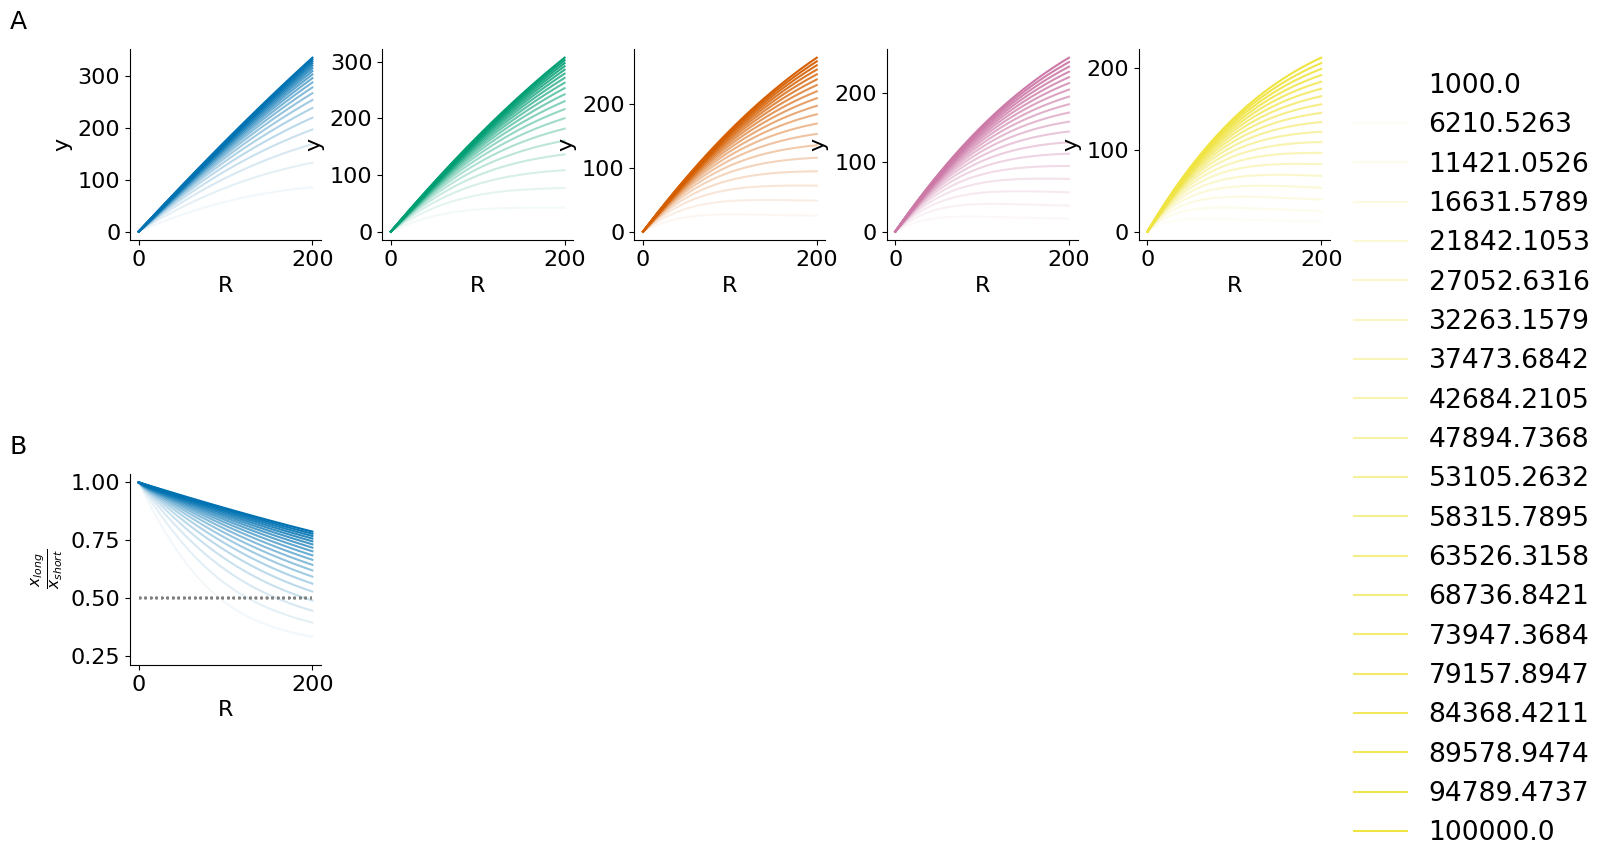

In [48]:
layout = '''
    AAAAAAAAAA
    AAAAAAAAAA
    BBBBBBBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,.1,1,.1,1,.1,1,.1,1,.1]

specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
avs = np.linspace(0,1, Ys.shape[0])

ax1 = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,2])
ax3 = fig.add_subplot(gs[0,4])
ax4 = fig.add_subplot(gs[0,6])
ax5 = fig.add_subplot(gs[0,8])
ax = fig.add_subplot(gs[2,0])
for i in range(Ys.shape[0]):

    av1 = np.mean(results_ys[i,:, -1, 2,s_1k], axis = 0)
    av2 = np.mean(results_ys[i,:, -1, 2,s_2k], axis = 0)
    av3 = np.mean(results_ys[i,:, -1, 2,s_3k], axis = 0)
    av4 = np.mean(results_ys[i,:, -1,2,s_4k], axis = 0)
    av5 = np.mean(results_ys[i,:, -1, 2,b_4k], axis = 0)

    rat1 = np.mean(results_ys[i,:, -1, 2,long_ind], axis = 0)/np.mean(results_ys[i,:, -1, 2,short_ind], axis = 0)

    ax1.plot(Rs, av1, color= palette[0], alpha = avs[i])
    ax2.plot(Rs, av2, color = palette[1], alpha = avs[i])
    ax3.plot(Rs, av3, color = palette[2], alpha = avs[i])
    ax4.plot(Rs, av4, color = palette[3], alpha = avs[i])
    ax5.plot(Rs, av5, label = np.round(Ys[i],4), color =palette[4], alpha = avs[i])
    ax.plot(Rs, rat1, color = palette[0], alpha = avs[i])
    ax.plot(Rs, Rs*0 + 0.5, linestyle = ':', color = 'grey')
    #ax1.set_ylim(0,2)
    #ax2.set_ylim(0,0.75)
    #ax3.set_ylim(0,0.4)
    #ax4.set_ylim(0,0.3)
    #ax5.set_ylim(0,0.25)
    #ax.set_ylim(0.2,0.8)
ax1.set_xlabel('R')
ax2.set_xlabel('R')
ax3.set_xlabel('R')
ax4.set_xlabel('R')
ax5.set_xlabel('R')
ax.set_xlabel('R')

ax1.set_ylabel('y')
ax2.set_ylabel('y')
ax3.set_ylabel('y')
ax4.set_ylabel('y')
ax5.set_ylabel('y')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
    

clear_axes(ax)
clear_axes(ax1)
clear_axes(ax2)
clear_axes(ax3)
clear_axes(ax4)
clear_axes(ax5)
ax5.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
plt.savefig(figures_path+'appfig5_Y_influence.pdf')      
plt.show()



In [14]:
results_ys.shape

(20, 20, 3, 100)

/tmp/ipykernel_930031/1804338535.py:40: RuntimeWarning: invalid value encountered in divide
  rat1 = np.mean(results_ys[i,:, 2,long_ind], axis = 0)/np.mean(results_ys[i,:, 2,short_ind], axis = 0)


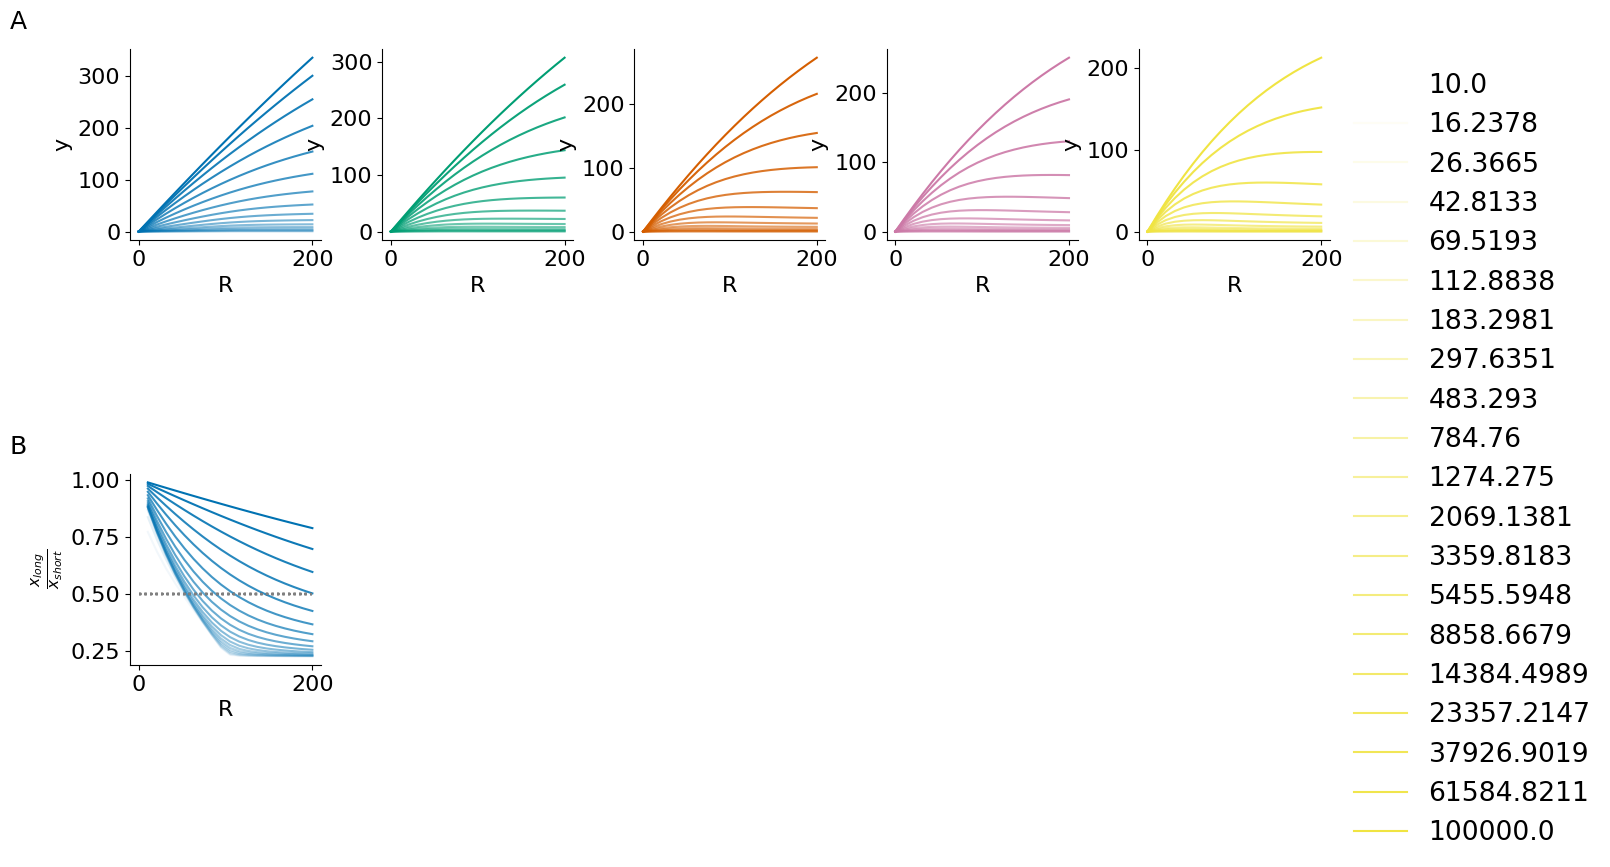

In [16]:
layout = '''
    AAAAAAAAAA
    AAAAAAAAAA
    BBBBBBBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,.1,1,.1,1,.1,1,.1,1,.1]

specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
avs = np.linspace(0,1, Ys.shape[0])

ax1 = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,2])
ax3 = fig.add_subplot(gs[0,4])
ax4 = fig.add_subplot(gs[0,6])
ax5 = fig.add_subplot(gs[0,8])
ax = fig.add_subplot(gs[2,0])
for i in range(Ys.shape[0]):

    av1 = np.mean(results_ys[i,:, 2,s_1k], axis = 0)
    av2 = np.mean(results_ys[i,:, 2,s_2k], axis = 0)
    av3 = np.mean(results_ys[i,:, 2,s_3k], axis = 0)
    av4 = np.mean(results_ys[i,:,2,s_4k], axis = 0)
    av5 = np.mean(results_ys[i,:, 2,b_4k], axis = 0)

    rat1 = np.mean(results_ys[i,:, 2,long_ind], axis = 0)/np.mean(results_ys[i,:, 2,short_ind], axis = 0)

    ax1.plot(Rs, av1, color= palette[0], alpha = avs[i])
    ax2.plot(Rs, av2, color = palette[1], alpha = avs[i])
    ax3.plot(Rs, av3, color = palette[2], alpha = avs[i])
    ax4.plot(Rs, av4, color = palette[3], alpha = avs[i])
    ax5.plot(Rs, av5, label = np.round(Ys[i],4), color =palette[4], alpha = avs[i])
    ax.plot(Rs, rat1, color = palette[0], alpha = avs[i])
    ax.plot(Rs, Rs*0 + 0.5, linestyle = ':', color = 'grey')
    #ax1.set_ylim(0,2)
    #ax2.set_ylim(0,0.75)
    #ax3.set_ylim(0,0.4)
    #ax4.set_ylim(0,0.3)
    #ax5.set_ylim(0,0.25)
    #ax.set_ylim(0.2,0.8)
ax1.set_xlabel('R')
ax2.set_xlabel('R')
ax3.set_xlabel('R')
ax4.set_xlabel('R')
ax5.set_xlabel('R')
ax.set_xlabel('R')

ax1.set_ylabel('y')
ax2.set_ylabel('y')
ax3.set_ylabel('y')
ax4.set_ylabel('y')
ax5.set_ylabel('y')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
    

clear_axes(ax)
clear_axes(ax1)
clear_axes(ax2)
clear_axes(ax3)
clear_axes(ax4)
clear_axes(ax5)
ax5.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
#plt.savefig(figures_path+'appfig5_Y_influence.pdf')      
plt.show()



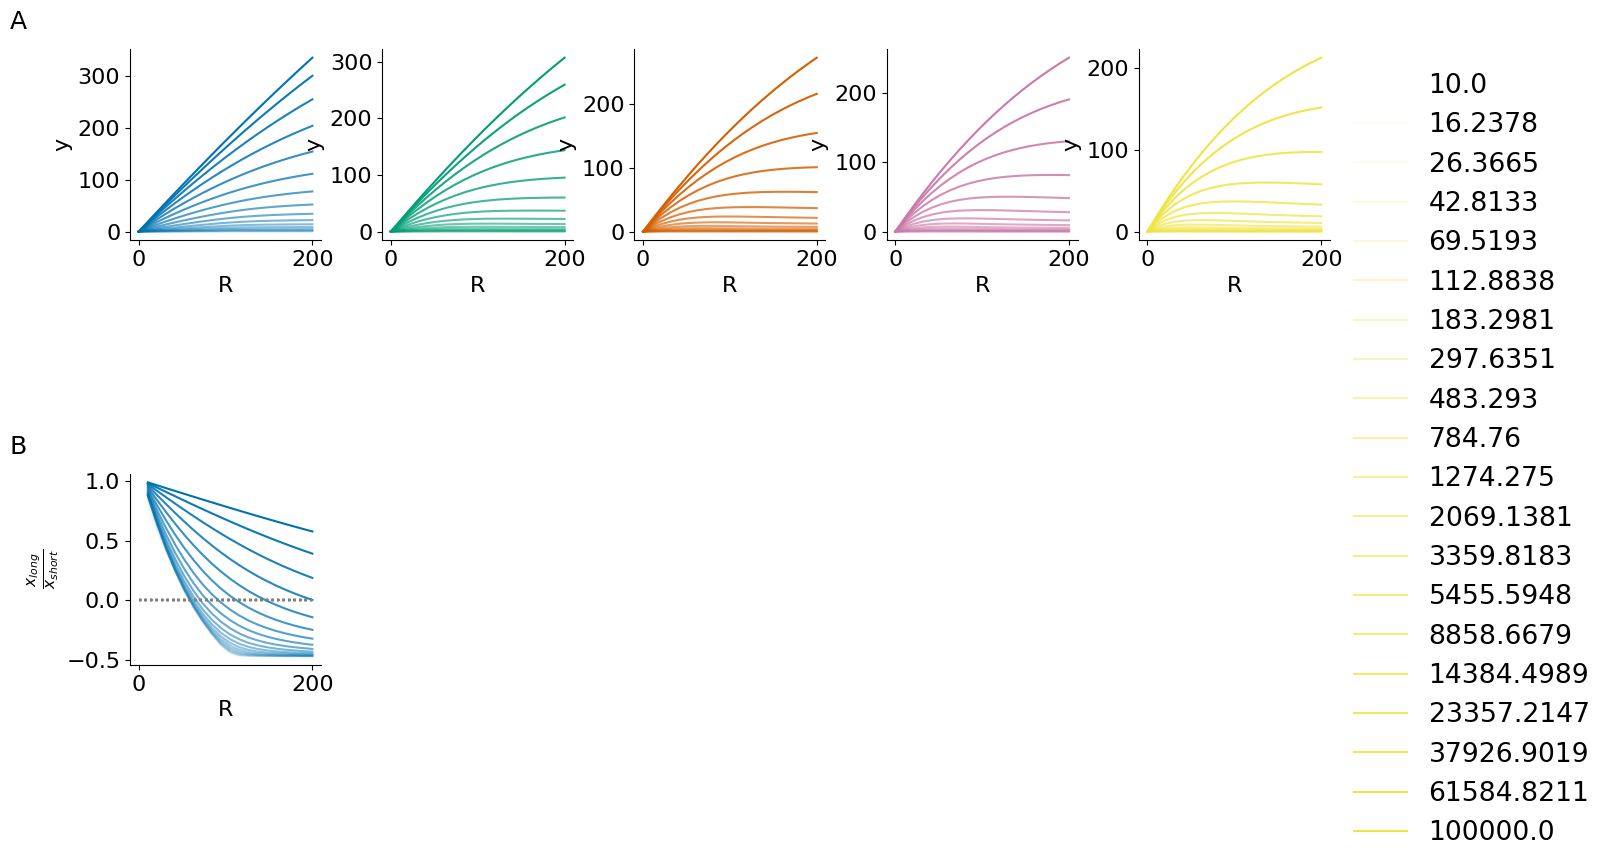

In [18]:
    
layout = '''
    AAAAAAAAAA
    AAAAAAAAAA
    BBBBBBBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,.1,1,.1,1,.1,1,.1,1,.1]

specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
avs = np.linspace(0,1, Ys.shape[0])

ax1 = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,2])
ax3 = fig.add_subplot(gs[0,4])
ax4 = fig.add_subplot(gs[0,6])
ax5 = fig.add_subplot(gs[0,8])
ax = fig.add_subplot(gs[2,0])
for i in range(Ys.shape[0]):

    av1 = np.mean(results_ys[i,:, 2,s_1k], axis = 0)
    av2 = np.mean(results_ys[i,:, 2,s_2k], axis = 0)
    av3 = np.mean(results_ys[i,:, 2,s_3k], axis = 0)
    av4 = np.mean(results_ys[i,:,2,s_4k], axis = 0)
    av5 = np.mean(results_ys[i,:, 2,b_4k], axis = 0)


    ax1.plot(Rs, av1, color= palette[0], alpha = avs[i])
    ax2.plot(Rs, av2, color = palette[1], alpha = avs[i])
    ax3.plot(Rs, av3, color = palette[2], alpha = avs[i])
    ax4.plot(Rs, av4, color = palette[3], alpha = avs[i])
    ax5.plot(Rs, av5, label = np.round(Ys[i],4), color =palette[4], alpha = avs[i])
    ax.plot(Rs[1:], calc_comp_score(results_ys[i,:, 2,long_ind],results_ys[i,:, 2,short_ind], diff_axis = 1, mean_axis = 0), color = palette[0], alpha = avs[i])
    ax.plot(Rs, Rs*0, linestyle = ':', color = 'grey')
    #ax1.set_ylim(0,2)
    #ax2.set_ylim(0,0.75)
    #ax3.set_ylim(0,0.4)
    #ax4.set_ylim(0,0.3)
    #ax5.set_ylim(0,0.25)
    #ax.set_ylim(0.2,0.8)
ax1.set_xlabel('R')
ax2.set_xlabel('R')
ax3.set_xlabel('R')
ax4.set_xlabel('R')
ax5.set_xlabel('R')
ax.set_xlabel('R')

ax1.set_ylabel('y')
ax2.set_ylabel('y')
ax3.set_ylabel('y')
ax4.set_ylabel('y')
ax5.set_ylabel('y')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
    

clear_axes(ax)
clear_axes(ax1)
clear_axes(ax2)
clear_axes(ax3)
clear_axes(ax4)
clear_axes(ax5)
ax5.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
#plt.savefig(figures_path+'appfig5_Y_influence.pdf')      
plt.show()



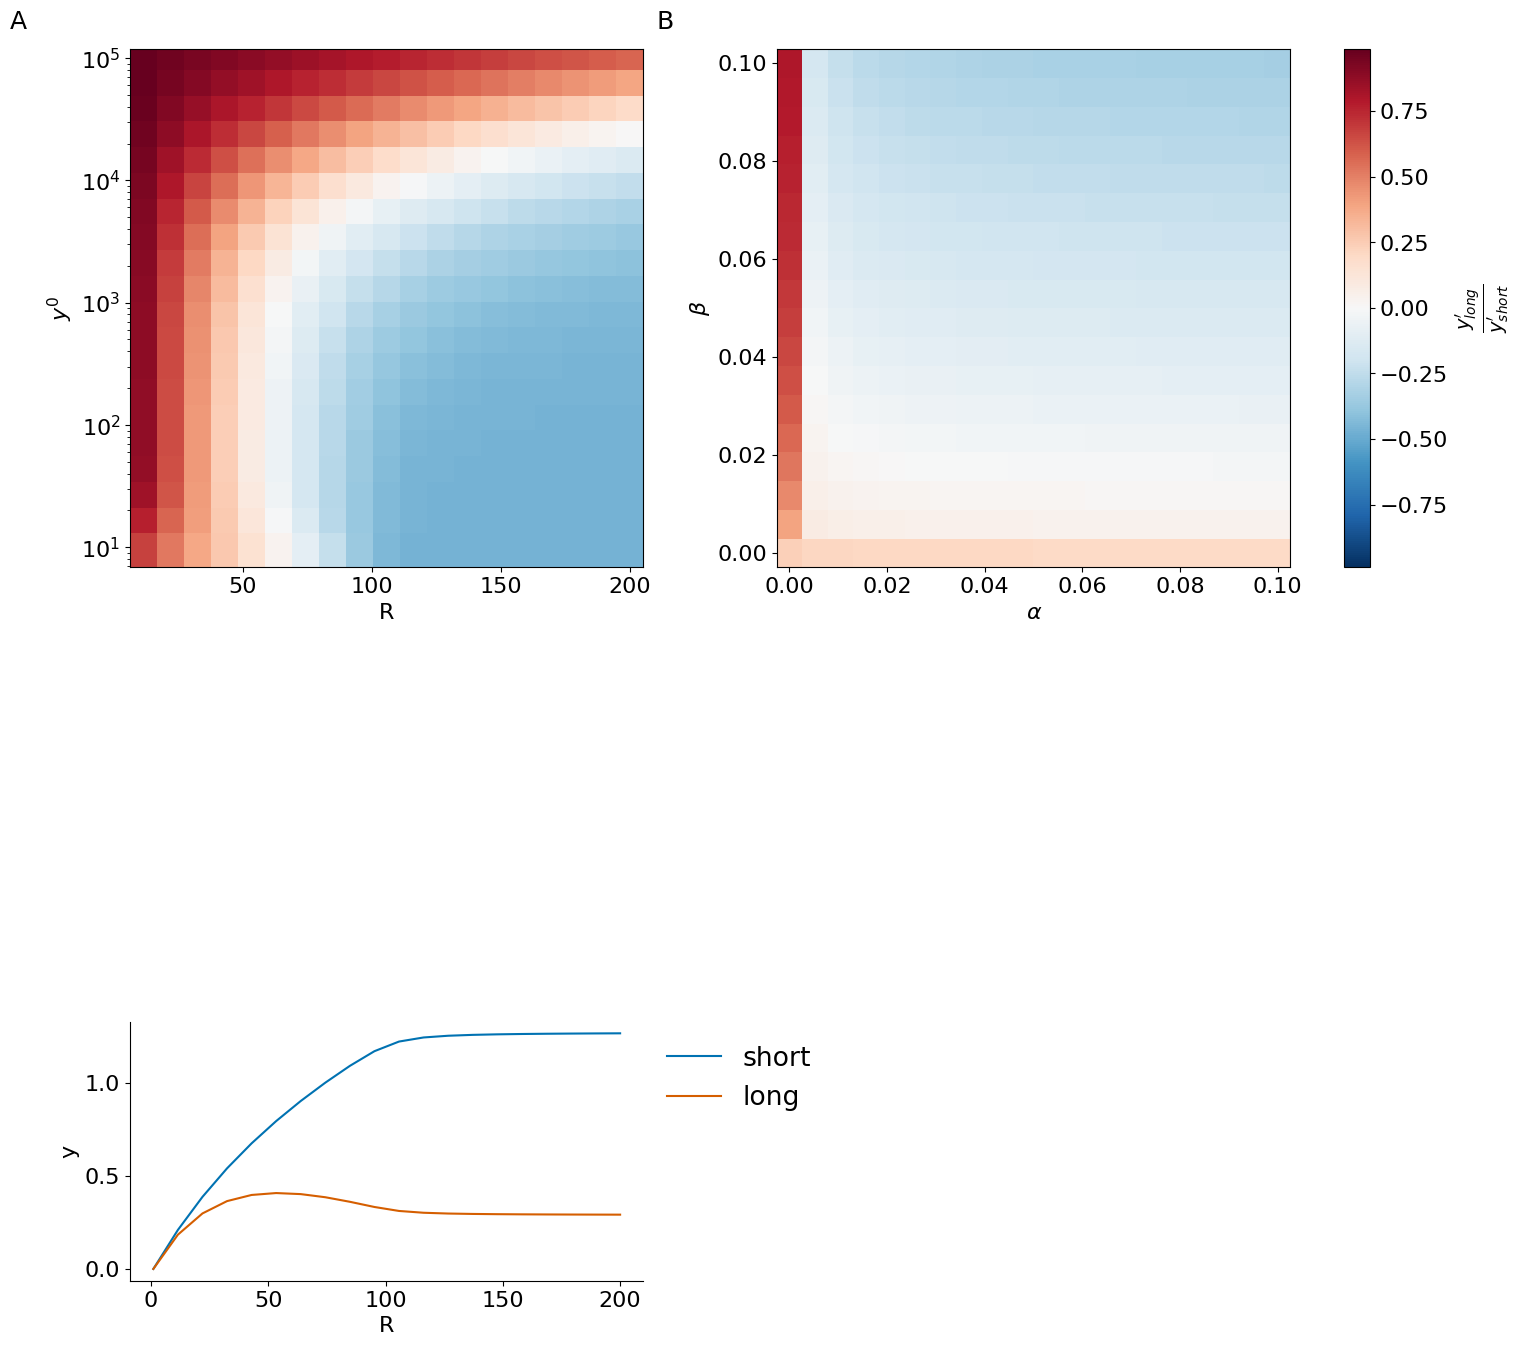

In [23]:
#do a heatmap which shows the different 

#if not wanting to run the parallelised competitions again, uncomment following line
results_ys = np.load('diff_data/ribo_amino_resource_interaction.npy')

interact_dat = np.load('diff_data/elongation_initiation_interaction_subsampled.npy')

Ys = np.logspace(1,5, num = 20)#np.arange(int(N/4),int(N*4), int(N/4))
Rs = np.linspace(1,200, num = 20)

α_samples = np.linspace(0.0001, 0.1, 20) #this ensures that we will have cases in which α < β
β_samples = np.linspace(0.0001, 0.1, 18)

#calculate all comp_scores
comp_c = np.zeros([Ys.shape[0], Rs.shape[0]-1])
for i in range(Ys.shape[0]): 
    comp_c[i] = calc_comp_score(results_ys[i,:, 2,long_ind],results_ys[i,:, 2,short_ind], diff_axis = 1, mean_axis = 0)
    
comp_c_inter = calc_comp_score(interact_dat[:,:,:,2, long_ind], interact_dat[:,:,:,2, short_ind], 2,3)


cmax = np.max(np.abs([np.min(comp_c), np.max(comp_c),np.min(comp_c_inter), np.max(comp_c_inter) ]))

layout = '''
AABB
AABB
AABB
'''

fig = plt.figure(figsize=(16, 16))

height_ratios = [2,0.1,1]
width_ratios = [1,.05, 1, .05]

specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()
    
ax = fig.add_subplot(gs[0:1,0])
ax.set_yscale('log')
hm = ax.pcolor(Rs[1:],Ys, comp_c, cmap = 'RdBu_r',shading='nearest',vmin = -cmax, vmax = cmax)#, extent = [Ys[0], Ys[-1], Rs[1], Rs[-1]])
#hm_ax = fig.add_subplot(gs[0:1,1])
cbar = fig.colorbar(hm, hm_ax)
cbar.ax.set_ylabel("$\\frac{y_{long}'}{y_{short}'}$", fontsize = 20)
ax.set_xlabel('R')
ax.set_ylabel('$y^0$')

ax = fig.add_subplot(gs[0:1,2])
#ax.set_yscale('log')
hm = ax.pcolor(α_samples,β_samples, comp_c_inter[:,:,1].T, cmap = 'RdBu_r',shading='nearest',vmin = -cmax, vmax = cmax)#, extent = [Ys[0], Ys[-1], Rs[1], Rs[-1]])
hm_ax = fig.add_subplot(gs[0:1,3])
cbar = fig.colorbar(hm, hm_ax)
cbar.ax.set_ylabel("$\\frac{y_{long}'}{y_{short}'}$", fontsize = 20)
ax.set_xlabel('$\\alpha$')
ax.set_ylabel('$\\beta$')

plot_y = 5
ax = fig.add_subplot(gs[2,0])
ax.plot(Rs, np.mean(results_ys[plot_y,:,2,short_ind], axis = 0), color = palette[0], label = 'short')
ax.plot(Rs, np.mean(results_ys[plot_y,:,2,long_ind], axis = 0), color = palette[2], label = 'long')

ax.set_ylabel('y')
ax.set_xlabel('R')
clear_axes(ax)
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
plt.savefig(figures_path+'fig5_heatmap_elong_init_interaction.pdf')

plt.show()